In [1]:
import numpy as np

np.random.seed(42)

<div style="font-family: 'Times New Roman', serif;">

**Mixed Normal Distribution**  

$$F_{NMIX}(x) =\sum_{i=1}^k w_i F_{\mathcal{N}}(\mu_i,\sigma_i^2), \quad w_i \geq 0, \quad \sum_{i=1}^k w_i = 1$$
for some $k\in \mathbb{N}$, where $F_{\mathcal{N}}$ is the CDF of the Normal distribution and  
$\mathbf{w} = (w_1, ..., w_k)$  
$\mu = (\mu_1, \mu_2, ...)$  
$\sigma^2 = (\sigma_1^2, \sigma_2^2, ...)$


*!! Not to be confused with Multivariate Normal Distribution*  

A **mixed normal distribution** is defined as the weighted sum of normal pdfs (or CDFs) with distinct parameters,  
where the weights represent the probabilities of different market regimes (or scenarios).  

When applied to *daily return data*, it captures key stylized facts such as fat tails (leptokurtosis) and skewness, much more effectively than a standard normal distribution.  

It is typically fitted to the *standardized residuals* after volatility clustering has been filtered out by a GARCH model, as standard mixture modeling assumes the observations are i.i.d..
</div>

In [2]:
n = 10000
mu = np.array([-0.2, 0.1, 0.1])
sig_sq = np.array([0.4, 0.1, 0.2])
sig = np.sqrt(sig_sq)
w = np.array([1/3, 1/3, 1/3])

# generate length n index list with weighted probability of w
components = np.random.choice(len(w), size = n, p = w)

# generate n samples mixed normal distribution. 
# each sample is drawn from different normal distributions (with weight w)
samples = np.random.normal(loc = mu[components],
                           scale = sig[components],
                           size = n) 



<div style="font-family: 'Times New Roman', serif;">

**Sample Unbiased estimators**
1. Sample mean
$$\bar{X} = \frac{1}{n} \sum_{j=1}^n X_j$$
2. Sample Variance
$$S^2 = \frac{1}{n - 1} \sum_{j=1}^n (X_j - \bar{X})^2$$

Note that an expectation of the unbiased estimator $\hat{\theta}$ is the true parameter
$$\mathbb{E}[\hat{\theta}] = \theta$$
</div>

In [3]:
# unbiased estimators (degree of freedom = 1)
sample_mean = np.mean(samples)
sample_var = np.var(samples, ddof = 1)
sample_std = np.std(samples, ddof = 1)

print(f"sample_mean: {sample_mean:.4f}")
print(f"sample_var: {sample_var:.4f}")
print(f"sample_std: {sample_std:.4f}")

sample_mean: 0.0050
sample_var: 0.2526
sample_std: 0.5026


<div style="font-family: 'Times New Roman', serif;">

The theoretical mean and variance of $X \sim NMIX(\mu, \sigma^2, w)$ is:  

1. Mean  
$$\mathbb{E}[X] = \sum_{i=1}^k w_i \mu_i$$
2. Variance  
$$\mathbb{V}[X] = \sum_{i=1}^k w_i \sigma_i^2 + \sum_{i=1}^k w_i (\mu_i - \bar{\mu})^2$$

</div>

In [4]:
theo_mean = sum(w*mu)
theo_var = sum(w*sig_sq) + sum(w*(mu - theo_mean)**2)
theo_std = np.sqrt(theo_var)

print(f"theo_mean: {theo_mean:.4f}")
print(f"theo_var: {theo_var:.4f}")
print(f"theo_std: {theo_std:.4f}")

theo_mean: 0.0000
theo_var: 0.2533
theo_std: 0.5033


<div style="font-family: 'Times New Roman', serif;">

Think of $X \sim NMIX(\mu, \sigma^2, w)$ as a daily return.  

The **Value-at-Risk** is then defined as: 
$$\operatorname{VaR}_\alpha(X) := -\inf \{ x \in \mathbb{R} : F_X(x) > \alpha \}$$
$\to$ negative of the $(1-\alpha)$-th quantile of $X$ (or the $\alpha$-th quantile of the loss $L=-X$)
</div>

In [5]:
alphas = [0.99, 0.95, 0.90]

for alpha in alphas:
    q = np.quantile(samples, 1-alpha)
    print(f"VaR at alpha = {int(alpha*100)}%: {-q:.4f}")


VaR at alpha = 99%: 1.4165
VaR at alpha = 95%: 0.8751
VaR at alpha = 90%: 0.6283


<div style="font-family: 'Times New Roman', serif;">

The estimated 99% VaR (~1.42) is significantly higher than that of a single normal distribution with the same mean and variance (~1.17)  
$\to$ reflects the fat-tailed (leptokurtic) nature of the normal mixture.

</div>

In [6]:
from scipy import stats
import matplotlib.pyplot as plt

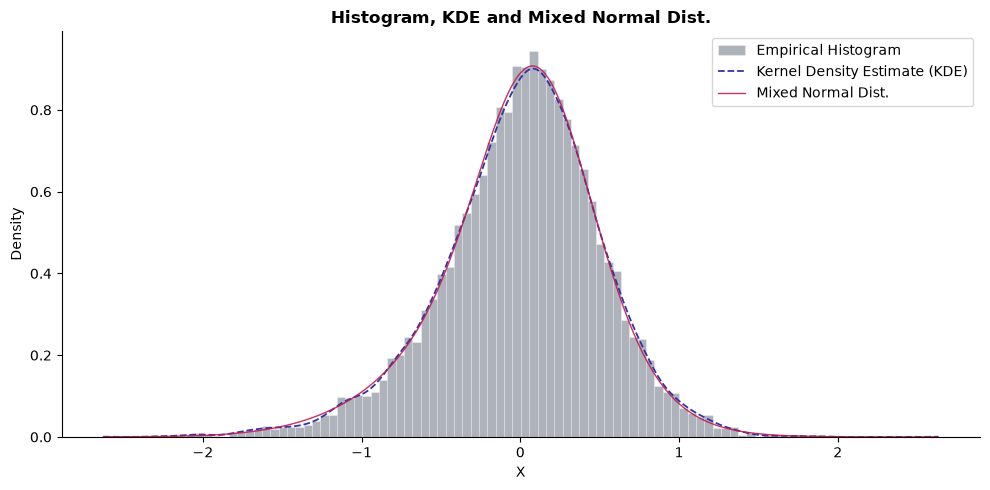

In [7]:
x_grid = np.linspace(samples.min(), samples.max() , 1000) 

# kernel density estimator (kernel function is chosen to be pdf of gaussian distribution)
kde = stats.gaussian_kde(samples) 
kde_pdf = kde(x_grid)

# true pdf of mixed normal distribution
true_pdf = np.zeros_like(x_grid)
for i in range(len(w)):
    true_pdf += w[i] * stats.norm.pdf(x_grid, loc = mu[i], scale = sig[i])


fig, ax = plt.subplots(figsize = (10,5), dpi=100)
# 1) histogram
ax.hist(
    samples,
    bins = 100,
    density = True,
    alpha = 0.45, color = "#4a5568", edgecolor = "white", linewidth = 0.5, 
    label = "Empirical Histogram"
)
# 2) Kernel Density Estimator
ax.plot(
    x_grid,
    kde_pdf,
    linestyle="--", color = "#3133AC", linewidth = 1.3, 
    label = "Kernel Density Estimate (KDE)"
)
# 3) True PDF (mixed normal)
ax.plot(
    x_grid,
    true_pdf,
    linestyle="-", color = "#C41A4D", linewidth = 1.0, alpha = 0.9,
    label = "Mixed Normal Dist."
)

ax.set_title("Histogram, KDE and Mixed Normal Dist.", fontweight = "bold")
ax.set_xlabel("X")
ax.set_ylabel("Density")
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()